# 4.4 Estudio piloto y tamaño de muestra

En esta sección estimamos la variación entre semillas con la configuración seleccionada y calculamos cuántas semillas $R$ se requieren para detectar una diferencia de $\delta = 0.02$ en F1 macro con potencia de 0.80.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config as C
from src import plots as P
from src.persist import is_done, load_pickle, save_pickle

P.setup()
C.ensure_dirs()
pd.set_option("display.precision", 4)
print("Resultados:", C.RESULTS.name, "| modelos:", ", ".join(C.MODELS))

Resultados: results | modelos: CNN, MobileNetV2, ResNet-18


In [2]:
RUN_TRAINING = False     # True solo si se quiere entrenar desde aquí; lo recomendado es la terminal

if RUN_TRAINING:
    import subprocess
    # Se lanza como proceso aparte: así el DataLoader con workers funciona en Windows y
    # una corrida interrumpida se reanuda igual que desde la terminal.
    subprocess.run([sys.executable, "-m", "src.runner", "pilot"], cwd=ROOT, check=False)
    subprocess.run([sys.executable, "-m", "src.runner", "power"], cwd=ROOT, check=False)

## Método

Para cada par de modelos $(A, B)$ y cada semilla $s$ del piloto calculamos la diferencia pareada del F1 macro de validación, $d_s = m_{A,s} - m_{B,s}$, y su desviación estándar $\hat\sigma_d$. El número de semillas para una prueba pareada bilateral es

$$R = \left\lceil \frac{\left(z_{1-\alpha/2} + z_{1-\beta}\right)^2 \hat\sigma_d^2}{\delta^2} \right\rceil, \qquad z_{0.975} + z_{0.80} = 2.802.$$

Tomamos el máximo sobre los tres pares y fijamos $R_{final} = \min(\max(R, 6), 10)$. El mínimo de 6 se debe a que, con 5 pares, la prueba de Wilcoxon bilateral no puede alcanzar $p < 0.0625$; el máximo de 10 corresponde al tiempo de cómputo disponible. Con $R_{final}$ semillas, la diferencia mínima detectable es

$$\text{MDE} = \frac{\left(z_{1-\alpha/2} + z_{1-\beta}\right)\hat\sigma_d}{\sqrt{R_{final}}}.$$

La fórmula se obtiene al exigir que la media de las $R$ diferencias, con error estándar $\sigma_d/\sqrt{R}$, supere el umbral de significancia en el 80 % de los experimentos cuando la diferencia real es $\delta$. Si MDE > δ, el experimento no tiene potencia suficiente para diferencias de tamaño δ.

In [3]:
pil = load_pickle(C.COMMON / "pilot.pkl")
pa = load_pickle(C.COMMON / "power_analysis.pkl")
print("F1 macro de validación por semilla (piloto):")
display(pil["tabla_ancha"].round(4))
display(pil["descriptivos"].rename(columns={"mean": "media", "std": "DE", "cv": "CV"}).round(4))

F1 macro de validación por semilla (piloto):


model,CNN,MobileNetV2,ResNet-18
seed,,,
0,0.8627,0.8388,0.8770
1,0.8431,0.8325,0.8826
2,0.8635,0.8356,0.8607
3,0.8583,0.8515,0.8794
4,0.8626,0.8740,0.8724


,media,DE,CV
model,,,
CNN,0.8580,0.0086,0.0100
MobileNetV2,0.8465,0.0170,0.0201
ResNet-18,0.8744,0.0085,0.0097


In [4]:
tabla_r = pa["tabla"].rename(columns={"par": "par (A − B)", "media_d": "media de d", "sd_d": "DE de d",
                                     "R_par": "R", "shapiro_p": "Shapiro-Wilk p"})
display(tabla_r[["par (A − B)", "n_piloto", "media de d", "DE de d", "R", "Shapiro-Wilk p"]].round(4))
display(pd.Series({"R calculado (máximo)": pa["R_calculado"], "R final": pa["R_final"],
                   "MDE con R final": round(pa["MDE"], 4), "delta": pa["delta"],
                   "MDE > delta": pa["MDE_supera_delta"], "limitado por R máximo": pa["limitado_por_R_max"]},
                  dtype=object).to_frame("valor"))

,par (A − B),n_piloto,media de d,DE de d,R,Shapiro-Wilk p
0,CNN - MobileNetV2,5,0.0116,0.0155,5,0.6825
1,CNN - ResNet-18,5,-0.0164,0.0156,5,0.9214
2,MobileNetV2 - ResNet-18,5,-0.0279,0.0192,8,0.7613


,valor
R calculado (máximo),8
R final,8
MDE con R final,0.019
delta,0.02
MDE > delta,False
limitado por R máximo,False


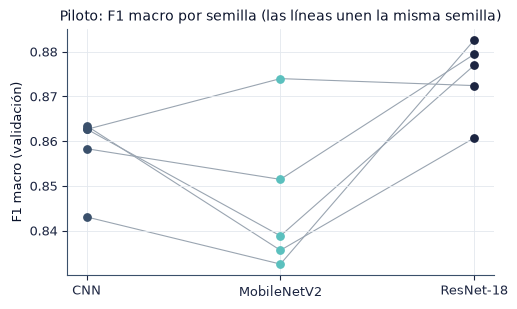

In [5]:
w = pil["tabla_ancha"]
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for s, row in w.iterrows():
    ax.plot(range(3), row.values, color="#9AA5B1", lw=0.8, zorder=1)
for i, m in enumerate(C.MODELS):
    ax.scatter(np.full(len(w), i), w[m], color=P.color(m), s=28, zorder=2, label=m)
ax.set_xticks(range(3), C.MODELS)
ax.set_ylabel("F1 macro (validación)")
ax.set_title("Piloto: F1 macro por semilla (las líneas unen la misma semilla)")
P.save(fig, "4_4_piloto_pareado", {"tabla": w})
plt.show()

In [6]:
normal = (pa["tabla"]["shapiro_p"] > C.ALPHA).all()
txt = [f"**Resultado.** La mayor desviación estándar de las diferencias pareadas en el piloto es "
       f"{pa['tabla']['sd_d'].max():.4f}, de donde R = {pa['R_calculado']}. Entrenamos {pa['R_final']} semillas por modelo."]
if pa["limitado_por_R_max"]:
    txt.append(f"El valor calculado supera el máximo de {pa['R_max']} que permite el tiempo de GPU.")
if pa["MDE_supera_delta"]:
    txt.append(f"Con {pa['R_final']} semillas, la diferencia mínima detectable es {pa['MDE']:.3f}, mayor que δ = {pa['delta']}: "
               "una diferencia real del tamaño de δ podría no resultar significativa, lo que constituye una limitación del experimento.")
else:
    txt.append(f"Con {pa['R_final']} semillas, la diferencia mínima detectable es {pa['MDE']:.3f}, menor o igual que δ = {pa['delta']}.")
txt.append("La prueba de Shapiro-Wilk no rechaza la normalidad de las diferencias en ningún par; con 5 datos su potencia es baja, "
           "por lo que reportamos tanto la t pareada como la prueba de Wilcoxon." if normal else
           "La prueba de Shapiro-Wilk rechaza la normalidad en al menos un par; la prueba principal por pares es Wilcoxon y la t pareada es complementaria.")
display(Markdown(" ".join(txt)))

**Resultado.** La mayor desviación estándar de las diferencias pareadas en el piloto es 0.0192, de donde R = 8. Entrenamos 8 semillas por modelo. Con 8 semillas, la diferencia mínima detectable es 0.019, menor o igual que δ = 0.02. La prueba de Shapiro-Wilk no rechaza la normalidad de las diferencias en ningún par; con 5 datos su potencia es baja, por lo que reportamos tanto la t pareada como la prueba de Wilcoxon.

## Conclusión

Las 5 semillas del piloto usan la configuración definitiva y forman parte del experimento final. El número de semillas se determinó con una regla fijada antes del entrenamiento, a partir del F1 macro de validación; el conjunto de prueba no intervino en ninguna decisión de diseño.